# Fruit & Veg Project 

In [1]:
!pip -q install imagehash pillow-heif tqdm 2>&1 | tail -1

[notice] To update, run: pip install --upgrade pip


## Settings & inputs

In [2]:
import os, re, io, json, shutil, zipfile, hashlib, random
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import imagehash
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
try:
    import pillow_heif; pillow_heif.register_heif_opener()   # phone HEIC photos
except Exception: pass

INPUTS = {
    "my_photos": "fruit_photos.zip",
}
# -------------------------------------------

SEED, IMG_SIZE = 42, 224
SPLIT = (0.70, 0.15, 0.15)                      # train / val / test
CLASSES = ["apple","banana","orange","lemon","tomato","carrot","cucumber","potato"]
ALIASES = {c: [c, c + "s"] for c in CLASSES}
ALIASES["tomato"] += ["tomatoes"]; ALIASES["potato"] += ["potatoes"]
EXCLUDE_TOKENS = {"rotten","rotting","spoiled","stale","juice","pie","sauce","logo","cartoon"}
IMG_EXTS = {".jpg",".jpeg",".png",".bmp",".webp",".heic"}
MIN_SIDE, MAX_SIDE = 64, 512
PHASH_THRESHOLD = 3          # Hamming distance (out of 64 bits) counted as "same image"
MIN_PER_CLASS = 20

DATA = Path("data"); RAW, CLEAN, META, REPORTS = DATA/"raw", DATA/"clean", DATA/"meta", Path("reports")
for p in (RAW, META, REPORTS): p.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

try:
    from google.colab import files; IN_COLAB = True
except ImportError:
    IN_COLAB = False

## Upload & extract

In [13]:
def prepare(source, path):
    """Return a folder for this input. Extracts zips; in Colab, prompts an upload if the file is missing."""
    path = Path(path).expanduser()
    if not path.exists() and IN_COLAB:
        print(f"Upload '{path.name}' for source '{source}':")
        up = files.upload()
        name = next(iter(up)); path = Path(name)
    assert path.exists(), f"'{path}' not found. Upload it (Colab: left Files panel) or fix INPUTS."
    if path.is_dir():
        return path
    dest = RAW / source
    if dest.exists(): shutil.rmtree(dest)
    with zipfile.ZipFile(path) as z:
        z.extractall(dest)
    return dest

def match_label(dir_parts, stem=""):
    tok = lambda s: set(t for t in re.split(r"[^a-z]+", s.lower()) if t)
    for part in list(reversed(dir_parts)) + ([stem] if stem else []):
        t = tok(part)
        if t & EXCLUDE_TOKENS: return None
        hits = [c for c in CLASSES if t & set(ALIASES[c])]
        if len(hits) == 1: return hits[0]
        if len(hits) > 1: return None
    return None

folders = {s: prepare(s, p) for s, p in INPUTS.items()}

# find every image, label it from its folder name
rows, unmatched = [], Counter()
for source, root in folders.items():
    for p in sorted(root.rglob("*")):
        if not p.is_file() or p.suffix.lower() not in IMG_EXTS or "__MACOSX" in p.parts: continue
        rel = p.relative_to(root)
        lab = match_label(rel.parts[:-1], p.stem)
        if lab is None: unmatched[rel.parts[0] if len(rel.parts) > 1 else "(top level)"] += 1
        rows.append(dict(source=source, label=lab, orig_path=p.as_posix()))
found = pd.DataFrame(rows)
print(f"{len(found)} images found")
display(found.groupby(["label","source"], dropna=False).size().unstack(fill_value=0))
if unmatched:
    print("Folders NOT matched to a class (edit CLASSES/ALIASES above if any of these are really fruit):")
    print(dict(unmatched.most_common(15)))
missing = [c for c in CLASSES if c not in set(found.label.dropna())]
if missing: print("\n No images found for:", missing)

596 images found


source,my_photos
label,
apple,112
banana,69
carrot,72
cucumber,70
lemon,62
orange,62
potato,80
tomato,69


## Clean
Unreadable / tiny / unlabeled files are dropped. Phone rotation (EXIF) is fixed, everything is converted to RGB
(transparent PNGs go on white) and downsized to max side 512. Clean copies go to `data/clean/<class>/`.

In [4]:
def load_rgb(path):
    with Image.open(path) as im:
        im.load(); im = ImageOps.exif_transpose(im); ow, oh = im.size
        if im.mode != "RGB":
            rgba = im.convert("RGBA"); bg = Image.new("RGB", rgba.size, (255,255,255))
            bg.paste(rgba, mask=rgba.getchannel("A")); im = bg
        else: im = im.copy()
    return im, ow, oh

if CLEAN.exists(): shutil.rmtree(CLEAN)
recs = []
for r in tqdm(found.to_dict("records"), desc="cleaning"):
    r.update(status="keep", reason="")
    if pd.isna(r["label"]):
        r.update(status="drop", reason="no_label"); recs.append(r); continue
    try: im, ow, oh = load_rgb(r["orig_path"])
    except Exception:
        r.update(status="drop", reason="corrupt_or_unreadable"); recs.append(r); continue
    if min(im.size) < MIN_SIDE:
        r.update(status="drop", reason="too_small"); recs.append(r); continue
    im.thumbnail((MAX_SIDE, MAX_SIDE), Image.LANCZOS)
    arr = np.asarray(im); gray = arr.mean(axis=2)
    uid = hashlib.sha1(arr.tobytes()).hexdigest()[:16]
    out = CLEAN / r["label"] / f"{uid}.jpg"; out.parent.mkdir(parents=True, exist_ok=True)
    if not out.exists(): im.save(out, quality=95)
    r.update(id=uid, clean_path=out.as_posix(), orig_w=ow, orig_h=oh, width=im.width, height=im.height,
             phash=str(imagehash.phash(im)), gray_mean=gray.mean(), gray_std=gray.std(),
             r_mean=arr[...,0].mean(), g_mean=arr[...,1].mean(), b_mean=arr[...,2].mean())
    recs.append(r)
man = pd.DataFrame(recs)
print(man[man.status=="drop"].reason.value_counts().to_string() or "nothing dropped in cleaning")

cleaning:   0%|          | 0/596 [00:00<?, ?it/s]

Series([], )


## Remove duplicates

In [14]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
hex_to_u64 = lambda hs: np.array([int(h, 16) for h in hs], dtype=np.uint64)
def popcount_xor(a, b):
    x = np.ascontiguousarray(np.bitwise_xor(a, b)); return POP[x.view(np.uint8).reshape(-1, 8)].sum(axis=1)
def near_pairs(h, thr):
    out = []
    for i in range(len(h)-1):
        d = popcount_xor(h[i+1:], h[i])
        out += [(i, i+1+int(j), int(d[j])) for j in np.nonzero(d <= thr)[0]]
    return out
def min_cross_distance(a, b):
    return 64 if len(a)==0 or len(b)==0 else min(int(popcount_xor(b, x).min()) for x in a)

ok = man.index[man.status=="keep"].to_numpy(); sub = man.loc[ok]
pairs = near_pairs(hex_to_u64(sub.phash), PHASH_THRESHOLD)
parent = list(range(len(sub)))
def find(x):
    while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
    return x
for i, j, _ in pairs: parent[find(i)] = find(j)
clusters = {}
for i in range(len(sub)): clusters.setdefault(find(i), []).append(i)
for members in clusters.values():
    if len(members) < 2: continue
    idx = [ok[m] for m in members]
    if man.loc[idx, "label"].nunique() > 1:
        man.loc[idx, ["status","reason"]] = ["drop","label_conflict"]; continue
    best = (man.loc[idx,"orig_w"] * man.loc[idx,"orig_h"]).idxmax()
    for i in idx:
        if i != best: man.loc[i, ["status","reason"]] = ["drop", "duplicate"]

dups = pd.DataFrame([dict(a=sub.iloc[i].orig_path, b=sub.iloc[j].orig_path, dist=d,
                          label_a=sub.iloc[i].label, label_b=sub.iloc[j].label) for i, j, d in pairs])
print(f"{len(pairs)} near-duplicate pairs found")
if len(dups):
    display(dups)
    show = dups.head(6)
    fig, ax = plt.subplots(len(show), 2, figsize=(5, 2.4*len(show)), squeeze=False)
    for k, r in enumerate(show.itertuples()):
        for c, p in enumerate((r.a, r.b)):
            ax[k, c].imshow(load_rgb(p)[0]); ax[k, c].axis("off"); ax[k, c].set_title(f"{r.label_a if c==0 else r.label_b} (d={r.dist})", fontsize=8)
    plt.suptitle("Spot-check: are these really the same photo?"); plt.tight_layout(); plt.show()

pool = man[man.status=="keep"].copy()
for f in CLEAN.rglob("*.jpg"):                               # delete clean files
    if f.as_posix() not in set(pool.clean_path): f.unlink()
print("\nRemoved overall:"); print(man[man.status=="drop"].reason.value_counts().to_string())
print("\nKept per class / source:"); display(pd.crosstab(pool.label, pool.source, margins=True))

0 near-duplicate pairs found

Removed overall:
reason
duplicate    21

Kept per class / source:


source,my_photos,All
label,,
apple,108,108
banana,68,68
carrot,69,69
cucumber,62,62
lemon,62,62
orange,61,61
potato,80,80
tomato,65,65
All,575,575


Flagged: 0


,id,label,source,flag


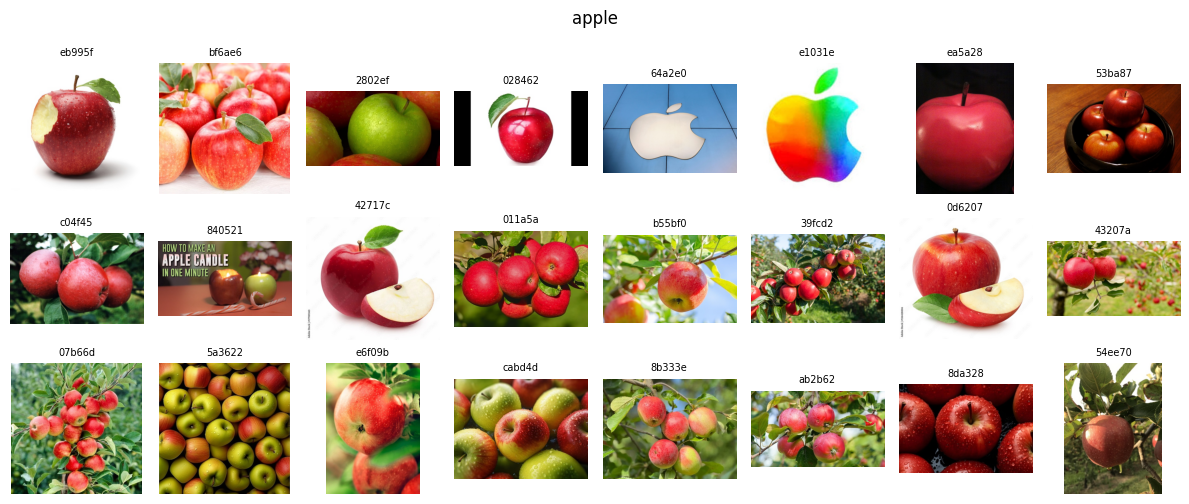

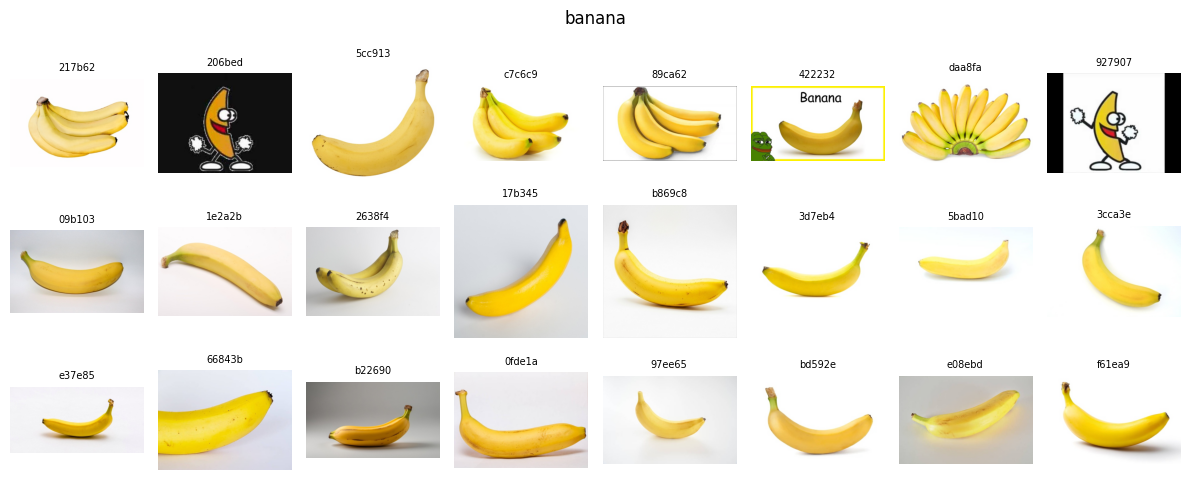

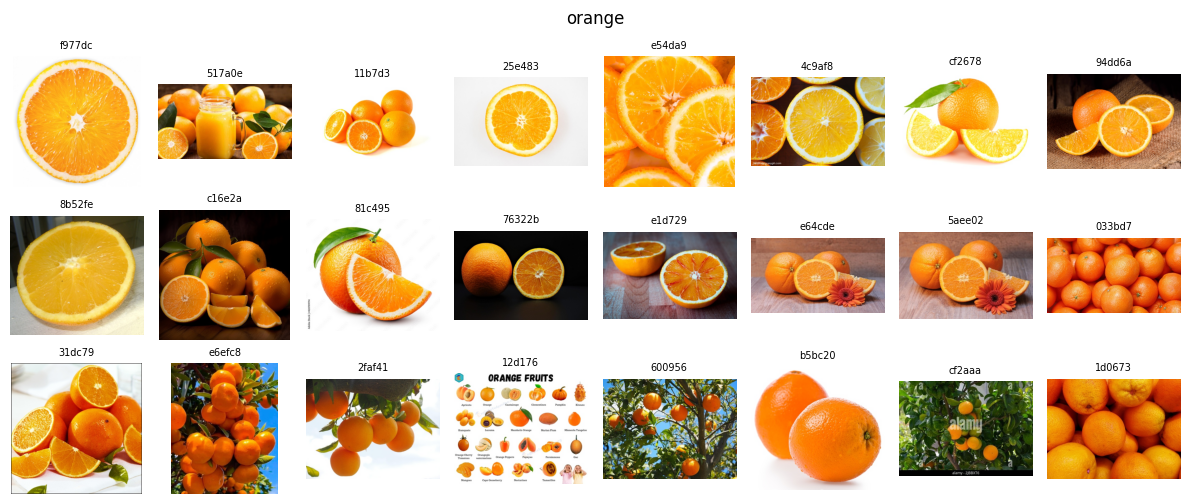

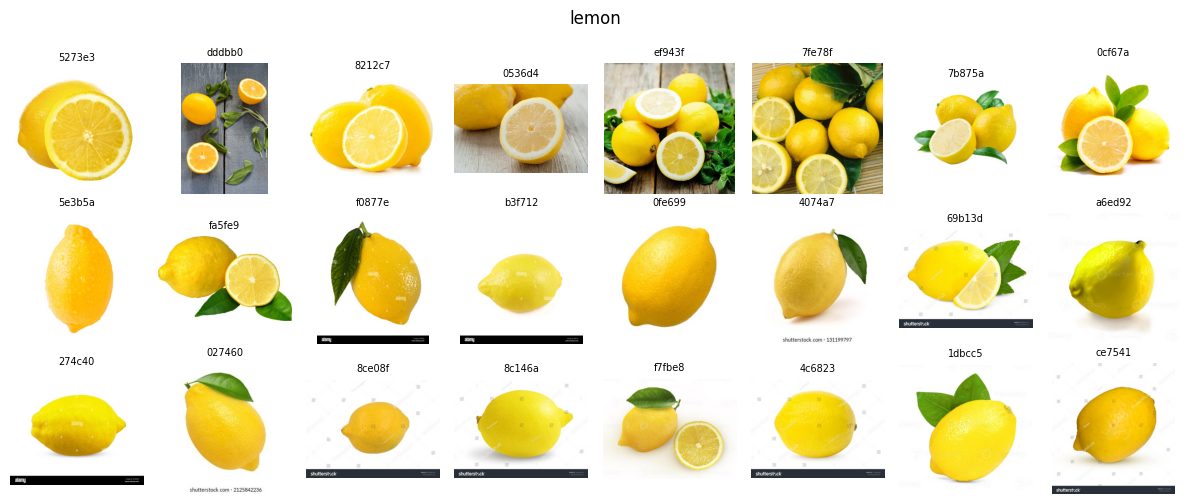

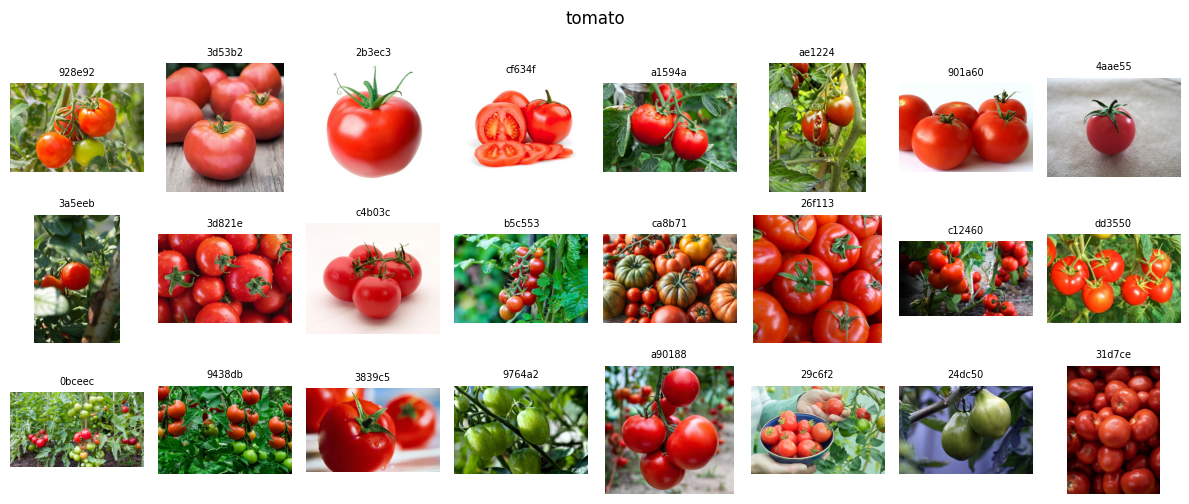

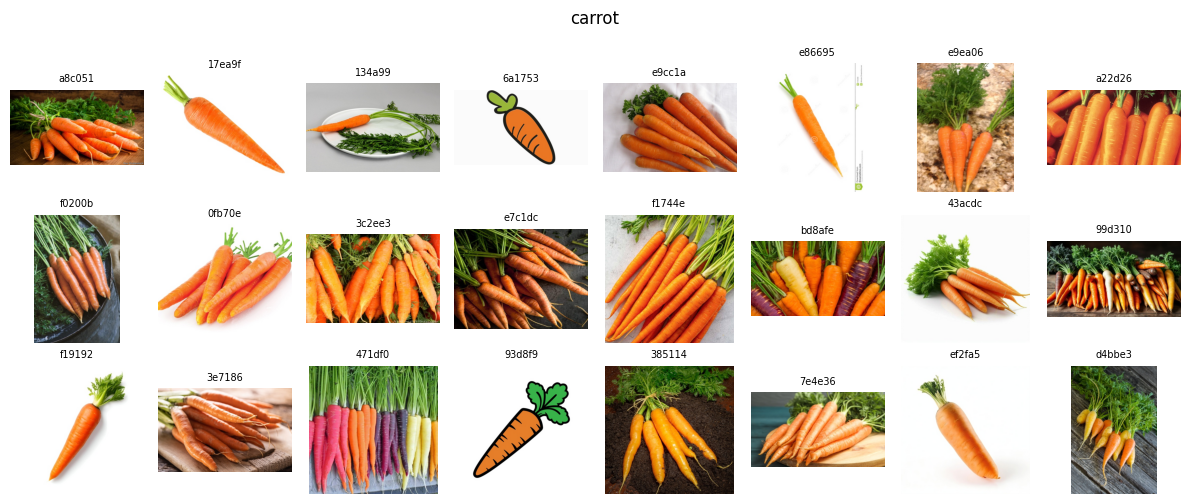

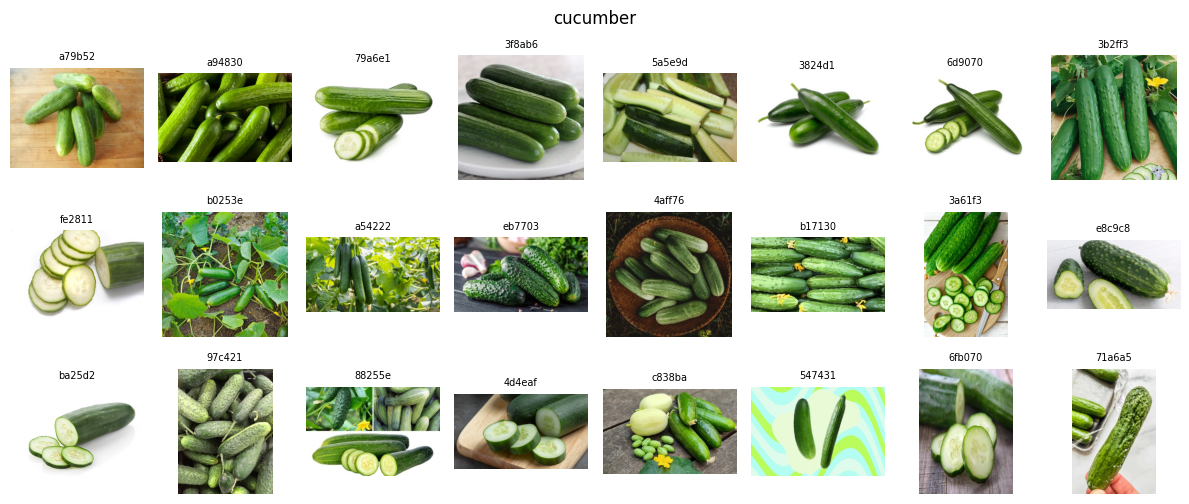

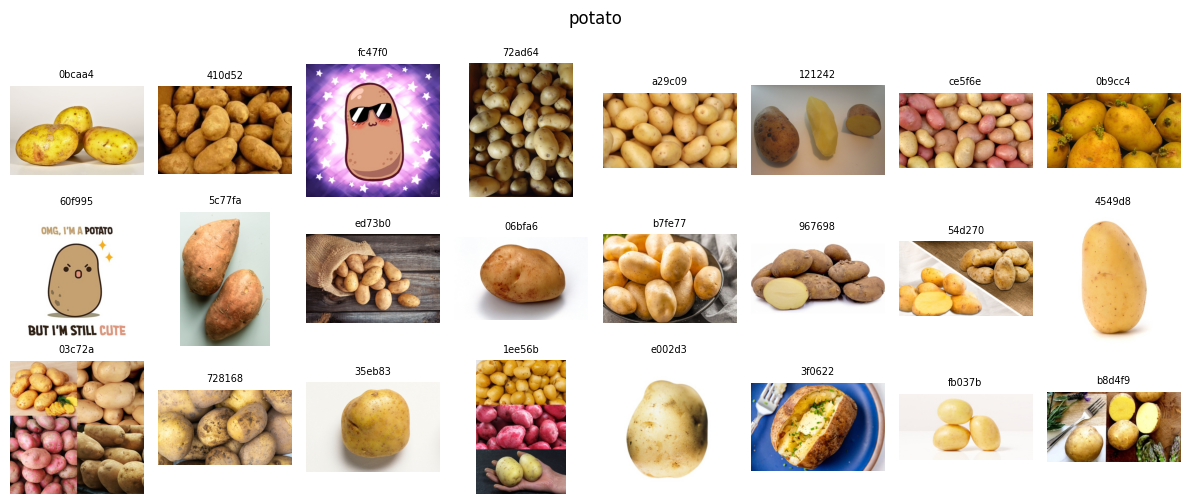

In [6]:
ar = pool.width / pool.height
pool["flag"] = ""
pool.loc[pool.gray_std < 12, "flag"] += "near_blank;"
pool.loc[(ar > 2.5) | (ar < 0.4), "flag"] += "extreme_aspect;"
pool.loc[pool[["width","height"]].min(axis=1) < 128, "flag"] += "small;"
print("Flagged:", (pool.flag != "").sum()); display(pool.loc[pool.flag != "", ["id","label","source","flag"]])

def contact_sheet(label, n=24, cols=8):
    g = pool[pool.label == label].head(n)
    rows_ = int(np.ceil(len(g)/cols)); fig, ax = plt.subplots(rows_, cols, figsize=(cols*1.5, rows_*1.7), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, r in zip(ax.ravel(), g.itertuples()):
        a.imshow(Image.open(r.clean_path)); a.set_title(r.id[:6], fontsize=7)
    plt.suptitle(label); plt.tight_layout(); plt.show()
for c in CLASSES:
    if (pool.label == c).any(): contact_sheet(c)

In [7]:
# Paste ids (the short 6-char titles above work too) of images to remove, then re-run this cell + everything below.
REMOVE_IDS = []   # e.g. ["a1b2c3", "d4e5f6"]
if REMOVE_IDS:
    bad = pool.id.str[:6].isin([i[:6] for i in REMOVE_IDS])
    for f in pool[bad].clean_path: Path(f).unlink(missing_ok=True)
    pool = pool[~bad]; print(f"removed {bad.sum()} images; {len(pool)} left")
pool = pool.drop(columns="flag"); pool.to_csv(META/"pool.csv", index=False); man.to_csv(META/"manifest.csv", index=False)

## Train / val / test split + leakage check

In [8]:
counts = pool.label.value_counts()
small = {c: int(counts.get(c, 0)) for c in CLASSES if counts.get(c, 0) < MIN_PER_CLASS}
assert not small, f"Need at least {MIN_PER_CLASS} images per class. Too few: {small}"

tr, rest = train_test_split(pool, test_size=SPLIT[1]+SPLIT[2], stratify=pool.label, random_state=SEED)
va, te = train_test_split(rest, test_size=SPLIT[2]/(SPLIT[1]+SPLIT[2]), stratify=rest.label, random_state=SEED)
splits = pd.concat([tr.assign(split="train"), va.assign(split="val"), te.assign(split="test")]).reset_index(drop=True)
assert splits.id.is_unique

H = {s: hex_to_u64(g.phash) for s, g in splits.groupby("split")}
for a, b in [("train","val"), ("train","test"), ("val","test")]:
    d = min_cross_distance(H[a], H[b]); assert d > PHASH_THRESHOLD, f"leak between {a} and {b}"
    print(f"min phash distance {a:>5} vs {b:<5}: {d}  OK")

class_to_idx = {c: i for i, c in enumerate(CLASSES)}
splits["label_idx"] = splits.label.map(class_to_idx)
splits[["id","clean_path","label","label_idx","source","split","phash","width","height"]].to_csv(META/"splits.csv", index=False)
json.dump(class_to_idx, open(META/"class_to_idx.json","w"), indent=2)
display(pd.crosstab(splits.label, splits.split, margins=True)[["train","val","test","All"]])

min phash distance train vs val  : 10  OK
min phash distance train vs test : 10  OK
min phash distance   val vs test : 10  OK


split,train,val,test,All
label,,,,
apple,76,16,16,108
banana,48,10,10,68
carrot,48,10,11,69
cucumber,43,10,9,62
lemon,43,9,10,62
orange,43,9,9,61
potato,56,12,12,80
tomato,45,10,10,65
All,402,86,87,575


## EDA

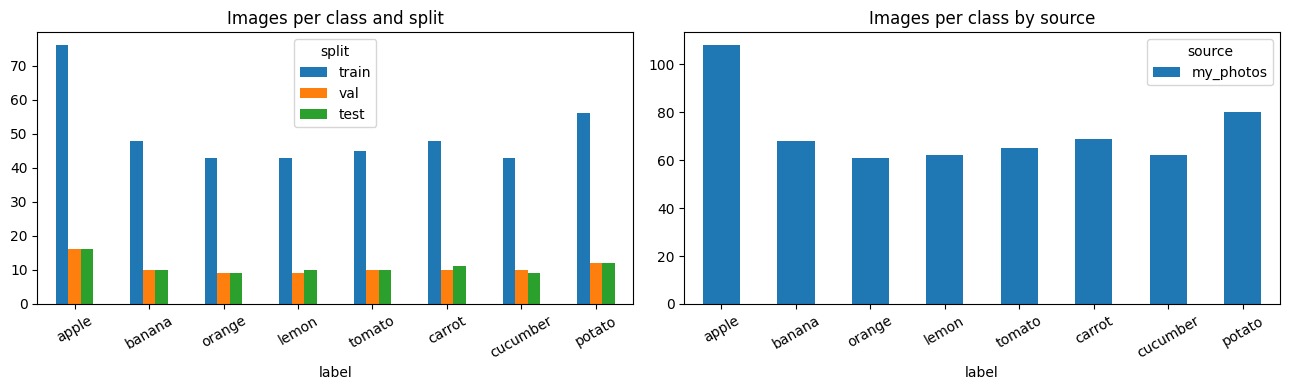

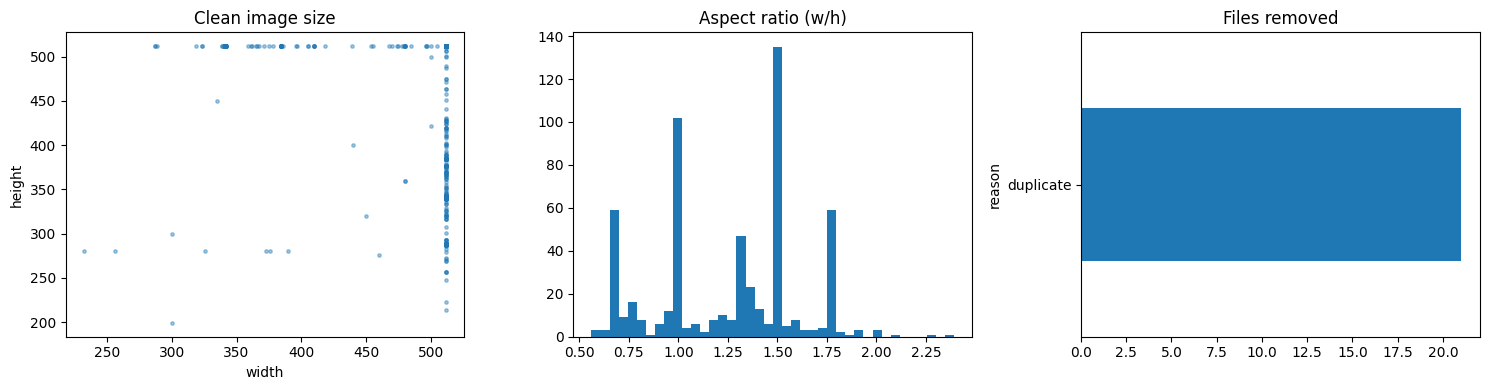

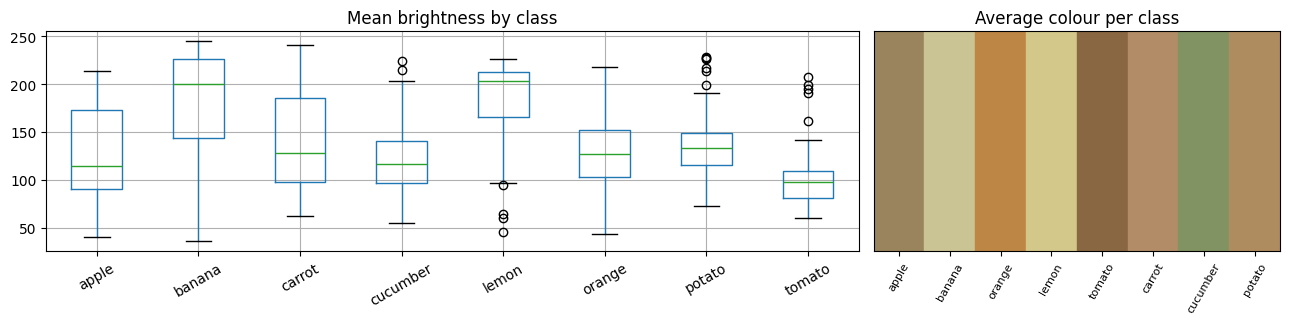

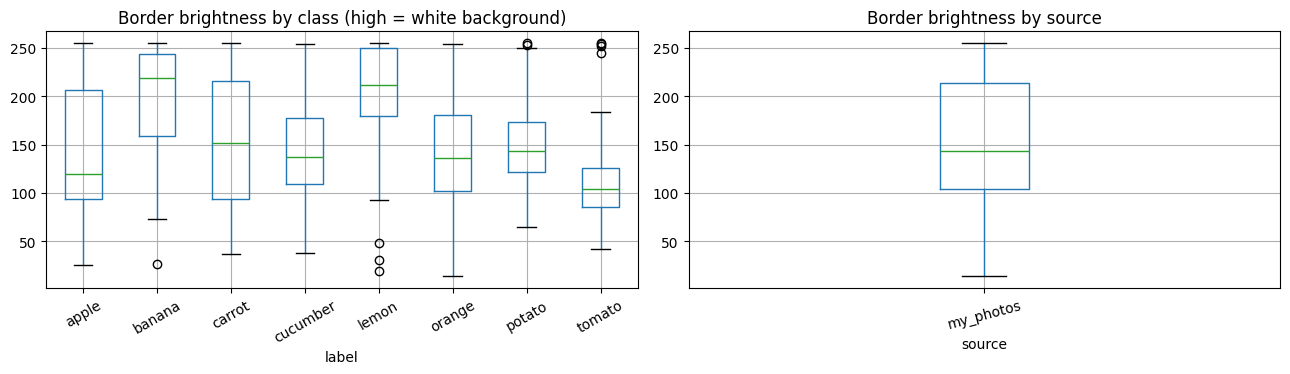

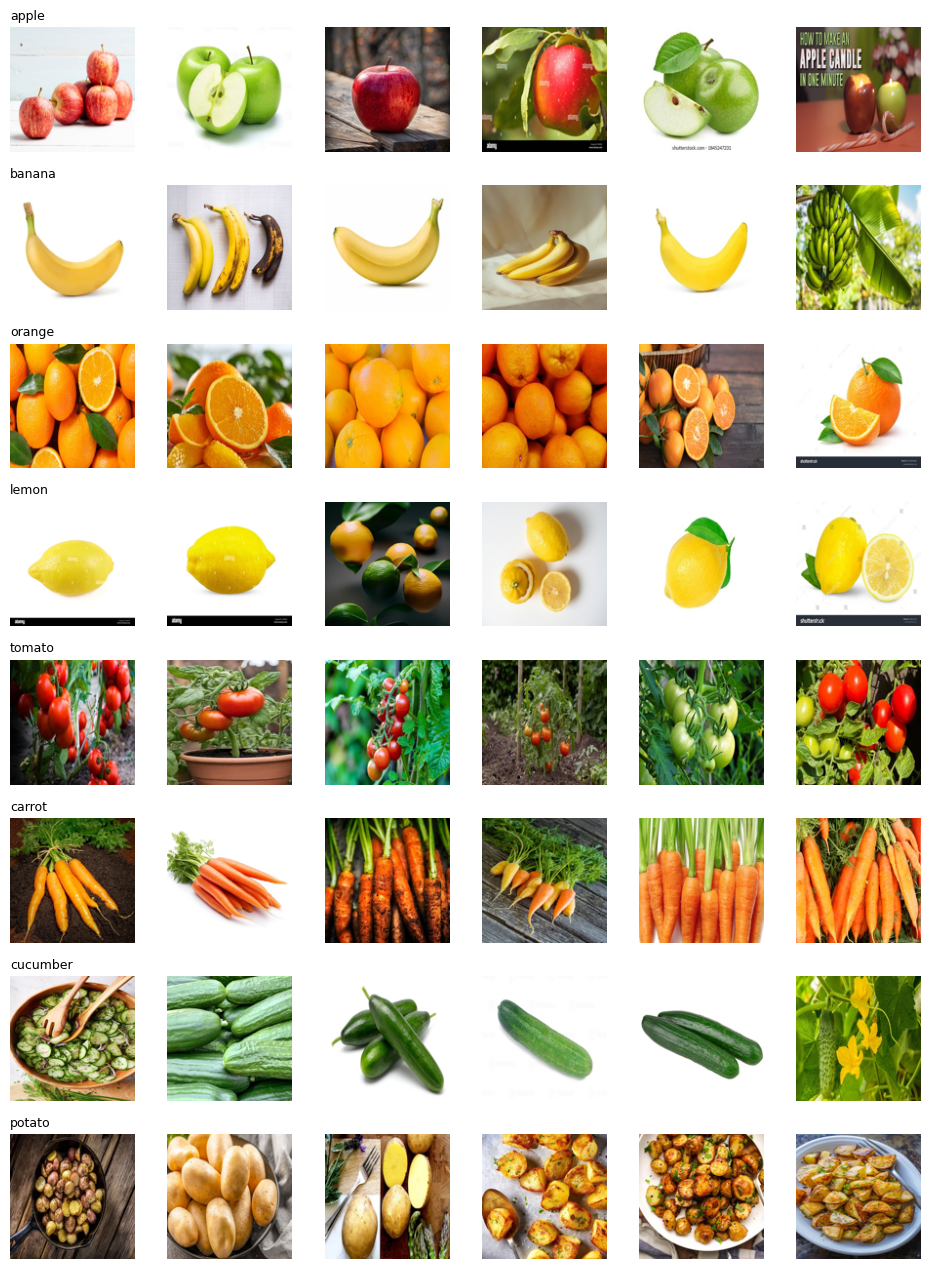

,n,brightness,border_bright,train,val,test
label,,,,,,
apple,108,126.5,140.3,76,16,16
banana,68,182.0,198.5,48,10,10
orange,61,130.9,142.3,43,9,9
lemon,62,182.6,199.3,43,9,10
tomato,65,102.1,112.8,45,10,10
carrot,69,140.3,153.2,48,10,11
cucumber,62,125.3,148.4,43,10,9
potato,80,137.0,151.7,56,12,12


In [9]:
df = splits
ct = pd.crosstab(df.label, df.split)[["train","val","test"]].reindex(CLASSES)
cs = pd.crosstab(df.label, df.source).reindex(CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ct.plot.bar(ax=ax[0], title="Images per class and split", rot=30); cs.plot.bar(stacked=True, ax=ax[1], title="Images per class by source", rot=30)
plt.tight_layout(); plt.savefig(REPORTS/"class_counts.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(df.width, df.height, s=6, alpha=.4); ax[0].set(title="Clean image size", xlabel="width", ylabel="height")
ax[1].hist(df.width/df.height, bins=40); ax[1].set(title="Aspect ratio (w/h)")
drops = man[man.status=="drop"].reason.value_counts()
(drops.plot.barh(ax=ax[2], title="Files removed") if len(drops) else ax[2].set_title("Nothing removed"))
plt.tight_layout(); plt.savefig(REPORTS/"sizes_and_drops.png", dpi=150); plt.show()

colors = (df.groupby("label")[["r_mean","g_mean","b_mean"]].mean().reindex(CLASSES) / 255).clip(0, 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), gridspec_kw={"width_ratios":[2,1]})
df.boxplot(column="gray_mean", by="label", ax=ax[0], rot=30); ax[0].set_title("Mean brightness by class"); ax[0].set_xlabel("")
for i, c in enumerate(CLASSES): ax[1].add_patch(plt.Rectangle((i,0),1,1,color=colors.loc[c].to_numpy()))
ax[1].set(xlim=(0,len(CLASSES)), ylim=(0,1), yticks=[], xticks=np.arange(len(CLASSES))+.5, title="Average colour per class")
ax[1].set_xticklabels(CLASSES, rotation=60, fontsize=8); plt.suptitle(""); plt.tight_layout()
plt.savefig(REPORTS/"brightness_color.png", dpi=150); plt.show()

# background shortcut check: white/studio background -> very bright borders
def border_brightness(p, k=6):
    g = np.asarray(Image.open(p).convert("L").resize((64,64)), dtype=float); m = np.ones_like(g, bool); m[k:-k, k:-k] = False
    return g[m].mean()
df["border_bright"] = [border_brightness(p) for p in df.clean_path]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df.boxplot(column="border_bright", by="label", ax=ax[0], rot=30); ax[0].set_title("Border brightness by class (high = white background)")
df.boxplot(column="border_bright", by="source", ax=ax[1], rot=15); ax[1].set_title("Border brightness by source")
plt.suptitle(""); plt.tight_layout(); plt.savefig(REPORTS/"background_check.png", dpi=150); plt.show()

rng = np.random.default_rng(SEED); n = 6
fig, axes = plt.subplots(len(CLASSES), n, figsize=(n*1.6, len(CLASSES)*1.6))
for r, c in enumerate(CLASSES):
    paths = df[df.label==c].clean_path.to_numpy(); pick = rng.choice(paths, size=min(n, len(paths)), replace=False)
    for k in range(n):
        axes[r,k].axis("off")
        if k < len(pick): axes[r,k].imshow(Image.open(pick[k]).resize((128,128)))
        if k == 0: axes[r,k].set_title(c, loc="left", fontsize=9)
plt.tight_layout(); plt.savefig(REPORTS/"sample_grid.png", dpi=150); plt.show()

summ = df.groupby("label").agg(n=("id","size"), brightness=("gray_mean","mean"), border_bright=("border_bright","mean")).reindex(CLASSES).round(1).join(ct)
summ.to_csv(REPORTS/"eda_summary.csv"); display(summ)

## Shared data loader (PyTorch)
Train-only augmentation, ImageNet normalization (needed for MobileNetV2/ResNet),
a fixed seed, and class weights if the classes end up unbalanced.

In [11]:
try:
    import torch
    from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
    from torchvision import transforms as T
    MEAN, STD = (0.485,0.456,0.406), (0.229,0.224,0.225)

    def build_transforms(train, size=IMG_SIZE):
        if train:
            return T.Compose([T.RandomResizedCrop(size, scale=(0.6,1.0), ratio=(0.8,1.25)), T.RandomHorizontalFlip(), T.RandomRotation(15),
                              T.ColorJitter(0.3, 0.3, 0.2, 0.02), T.ToTensor(), T.Normalize(MEAN, STD)])
        return T.Compose([T.Resize((size,size)), T.ToTensor(), T.Normalize(MEAN, STD)])

    class FruitVegDataset(Dataset):
        def __init__(self, split, transform=None, csv=META/"splits.csv"):
            d = pd.read_csv(csv); self.df = d[d.split==split].reset_index(drop=True)
            self.tf = transform or build_transforms(split=="train")
        def __len__(self): return len(self.df)
        def __getitem__(self, i):
            r = self.df.iloc[i]; return self.tf(Image.open(r.clean_path).convert("RGB")), int(r.label_idx)

    def class_weights(split="train"):
        n = pd.read_csv(META/"splits.csv").query("split == @split").label_idx.value_counts().reindex(range(len(CLASSES))).fillna(1).to_numpy()
        return torch.tensor(n.sum()/(len(CLASSES)*n), dtype=torch.float32)

    def get_dataloaders(batch_size=32, num_workers=2, balanced_sampler=False):
        torch.manual_seed(SEED); g = torch.Generator(); g.manual_seed(SEED)
        tr_ds = FruitVegDataset("train"); sampler = None
        if balanced_sampler:
            w = class_weights().numpy()[tr_ds.df.label_idx.to_numpy()]; sampler = WeightedRandomSampler(w, len(w), generator=g)
        return (DataLoader(tr_ds, batch_size, shuffle=sampler is None, sampler=sampler, num_workers=num_workers, generator=g),
                DataLoader(FruitVegDataset("val"), batch_size, num_workers=num_workers),
                DataLoader(FruitVegDataset("test"), batch_size, num_workers=num_workers))

    def load_split_numpy(split, size=IMG_SIZE):
        d = pd.read_csv(META/"splits.csv").query("split == @split")      # for the colour-histogram baseline
        return np.stack([np.asarray(Image.open(p).convert("RGB").resize((size,size))) for p in d.clean_path]), d.label_idx.to_numpy()

    xb, yb = next(iter(get_dataloaders(batch_size=8, num_workers=0)[0]))
    print("loader OK:", tuple(xb.shape), yb.tolist())
except ImportError:
    print("torch/torchvision not installed here - loader cell skipped (splits.csv is still ready).")

loader OK: (8, 3, 224, 224) [5, 5, 1, 0, 1, 5, 0, 5]


## Export

In [15]:
shutil.make_archive("fruitveg_dataset", "zip", root_dir=".", base_dir="data/clean")
shutil.copy(META/"splits.csv", "splits.csv"); shutil.copy(META/"class_to_idx.json", "class_to_idx.json")
print("Created fruitveg_dataset.zip (images) + splits.csv + class_to_idx.json")
if IN_COLAB:
    for f in ["fruitveg_dataset.zip", "splits.csv", "class_to_idx.json"]: files.download(f)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Created fruitveg_dataset.zip (images) + splits.csv + class_to_idx.json
